<div align="center">

<h1><strong>KECERDASAN ARTIFISIAL UNTUK GEOFISIKA</strong></h1>
<h3><strong>Implementasi Resep Komputasi Geofisika</strong></h3>

<img src="https://www.unhas.ac.id/wp-content/uploads/2022/09/Logo-Resmi-Unhas-1.png" 
     alt="Logo Universitas Hasanuddin" 
     style="width:250px; margin:20px 0;">


<br>

<h3><strong>Disusun Oleh:</h3><strong>
<ul style="list-style:none; padding-left:0; line-height:1.8; width:400px;">
  <li style="display:flex; justify-content:space-between;"><span>BASO MUH ALIFKA AGNUR</span><span>(H061241015)</span></li>
</ul>

<br><br>
<p><strong>PRODI GEOFISIKA</strong></p>
<p><strong>FAKULTAS MATEMATIKA DAN ILMU PENGETAHUAN ALAM</strong></p>
<p><strong>UNIVERSITAS HASANUDDIN</strong></p>
<p><strong>MAKASSAR</strong></p>
<p><strong>2026</strong></p>

</div>

---


**Daftar Resep yang Dipilih dari Buku AI Cookbook / Codex:**
1. **Resep 1 (`R-CS-004`)**: Case Study Pemodelan Perambatan Gelombang Seismik Akustik 1D (*Acoustic Wave Equation & Synthetic Seismogram*)
2. **Resep 2 (`R-MOD-001`)**: Case Study Simulasi Difusi Panas Bawah Permukaan 1D (*Subsurface Heat Diffusion Model & Analytic Validation*)


### Petunjuk Penggunaan:
Notebook ini dibuat secara *self-contained* (mandiri). Seluruh parameter fisik geofisika, fungsi numerik, serta pembuatan visualisasi telah terintegrasi sehingga dapat langsung dijalankan dengan memilih **Run All** di Jupyter Notebook atau Google Colab.

## BAGIAN 1: RESEP 1 (`R-CS-004`)
### Case Study: Pemodelan Perambatan Gelombang Seismik Akustik 1-D

#### 1. Latar Belakang Teori Geofisika
Dalam eksplorasi seismik, gelombang seismik yang merambat melalui media batuan homogen dapat didekati menggunakan persamaan gelombang akustik 1 dimensi:
$$\frac{\partial^2 u(x, t)}{\partial t^2} = v^2 \frac{\partial^2 u(x, t)}{\partial x^2} + s(x, t)$$
di mana:
- $u(x, t)$ = perpindahan partikel (*displacement*)
- $v$ = kecepatan gelombang akustik P ($m/s$)
- $s(x, t)$ = fungsi sumber getaran seismik (menggunakan *Ricker Wavelet*)

#### 2. Kondisi Kestabilan Courant-Friedrichs-Lewy (CFL)
Metode beda hingga (*Finite Difference Method*) memerlukan batasan kestabilan numerik:
$$CFL = \frac{v \cdot \Delta t}{\Delta x} \le 1.0$$
Jika $CFL > 1.0$, solusi numerik akan mengalami ledakan (*blow up*) dan tidak stabil.

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# 1. Fungsi Sumber Ricker Wavelet
def ricker_wavelet(t, f0, t0):
    """Membangkitkan wavelet Ricker seismik."""
    tau = np.pi * f0 * (t - t0)
    return (1.0 - 2.0 * tau**2) * np.exp(-tau**2)

# 2. Parameter Model Geofisika Seismik
length_m = 1200.0         # Panjang domain penelitian (meter)
dx_m = 2.0                # Spasi grid spasial (meter)
velocity_m_s = 1500.0     # Kecepatan gelombang P pada media (m/s, contoh: lapisan sedimen/air)
duration_s = 0.6          # Durasi perekaman seismik (detik)
dt_s = 0.0008             # Interval sampling waktu (detik)

source_x_m = 600.0        # Posisi sumber getar (shotpoint) di tengah domain
source_f0 = 25.0          # Frekuensi dominan sumber (25 Hz)
source_t0 = 0.08          # Time delay puncak wavelet (detik)

receiver_positions = [650.0, 750.0, 900.0, 1050.0]  # Posisi geophone receiver (offset jarak)
snapshot_times = [0.10, 0.20, 0.30]                 # Waktu perekaman snapshot medan gelombang

# 3. Grid Koordinat dan Pengecekan Kestabilan CFL
x = np.arange(0.0, length_m + dx_m, dx_m)
cfl = velocity_m_s * dt_s / dx_m
nsteps = int(round(duration_s / dt_s))

print(f"=== PARAMETER RESEP R-CS-004 ===")
print(f"Jumlah titik grid (Nx): {len(x)}")
print(f"Jumlah langkah waktu (Nt): {nsteps}")
print(f"Nilai CFL: {cfl:.4f} (Status: {'Stabil' if cfl <= 1.0 else 'TIDAK STABIL!'})")

=== PARAMETER RESEP R-CS-004 ===
Jumlah titik grid (Nx): 601
Jumlah langkah waktu (Nt): 750
Nilai CFL: 0.6000 (Status: Stabil)


In [8]:
# 4. Simulasi Pemodelan Beda Hingga (FDM)
source_idx = int(np.argmin(np.abs(x - source_x_m)))
receiver_indices = [int(np.argmin(np.abs(x - rx))) for rx in receiver_positions]
snapshot_steps = {int(round(t / dt_s)): t for t in snapshot_times}

u_prev = np.zeros_like(x)
u_curr = np.zeros_like(x)

seismograms = {rx: [] for rx in receiver_positions}
time_records = []
snapshots_record = {}

for step in range(nsteps + 1):
    t_curr = step * dt_s
    time_records.append(t_curr)
    
    # Catat respons perpindahan di masing-masing receiver geophone
    for rx_pos, rx_idx in zip(receiver_positions, receiver_indices):
        seismograms[rx_pos].append(u_curr[rx_idx])
        
    # Simpan snapshot medan gelombang
    if step in snapshot_steps:
        snapshots_record[snapshot_steps[step]] = u_curr.copy()
        
    if step == nsteps:
        break
        
    # Pembaruan skema beda hingga orde 2 (FDM Time Stepping)
    u_next = np.zeros_like(u_curr)
    u_next[1:-1] = (2.0 * u_curr[1:-1] - u_prev[1:-1] 
                    + (cfl**2) * (u_curr[2:] - 2.0 * u_curr[1:-1] + u_curr[:-2]))
    
    # Injeksi wavelet sumber seismik
    u_next[source_idx] += ricker_wavelet(t_curr, source_f0, source_t0)
    
    # Geser matriks waktu
    u_prev, u_curr = u_curr, u_next

print("Simulasi perambatan gelombang seismik selesai dijalankan!")

Simulasi perambatan gelombang seismik selesai dijalankan!


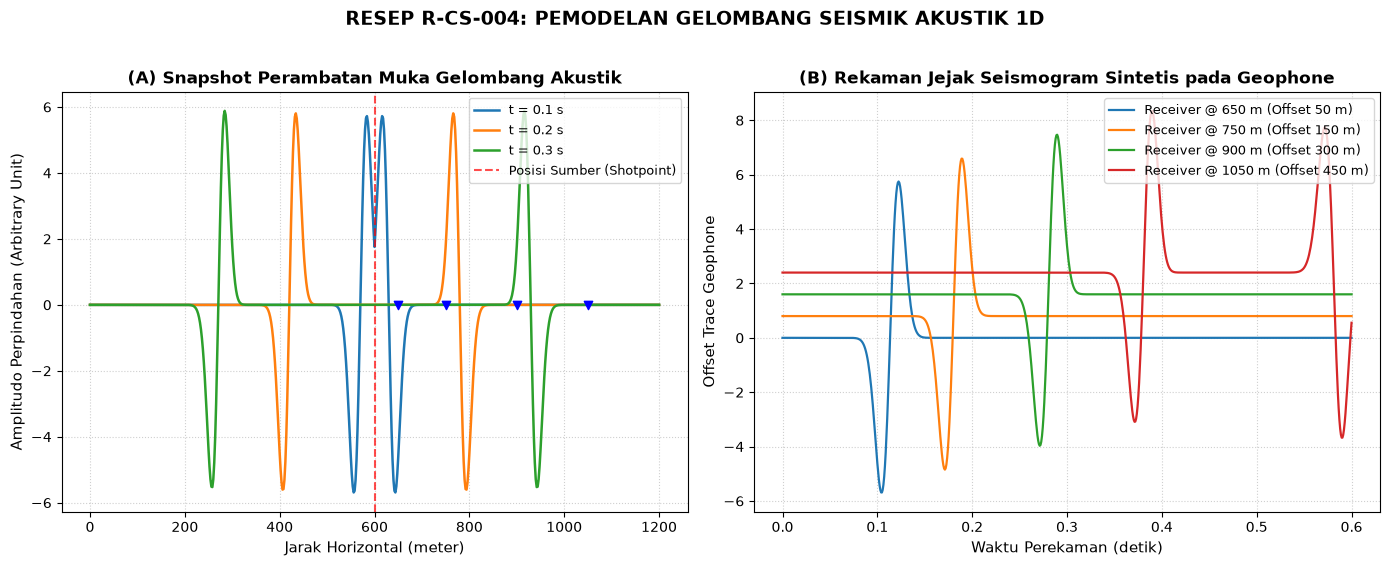

In [9]:
# 5. Visualisasi Hasil Pemodelan Gelombang Seismik
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot A: Snapshot Muka Gelombang (Wavefield Profile)
for t_snap, wavefield in snapshots_record.items():
    axes[0].plot(x, wavefield, label=f"t = {t_snap} s", linewidth=1.8)
axes[0].axvline(source_x_m, color='red', linestyle='--', alpha=0.7, label="Posisi Sumber (Shotpoint)")
for rx in receiver_positions:
    axes[0].scatter(rx, 0, color='blue', marker='v', zorder=5)
axes[0].set_title("(A) Snapshot Perambatan Muka Gelombang Akustik", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Jarak Horizontal (meter)", fontsize=11)
axes[0].set_ylabel("Amplitudo Perpindahan (Arbitrary Unit)", fontsize=11)
axes[0].grid(True, linestyle=":", alpha=0.6)
axes[0].legend(loc="upper right", fontsize=9)

# Subplot B: Jejak Seismogram Sintetis (Synthetic Seismograms)
for i, rx in enumerate(receiver_positions):
    trace = np.array(seismograms[rx])
    # Normalisasi dan beri offset visual agar jejak tidak bertumpuk
    axes[1].plot(time_records, trace + i * 0.8, label=f"Receiver @ {rx:.0f} m (Offset {rx-source_x_m:.0f} m)", linewidth=1.6)
axes[1].set_title("(B) Rekaman Jejak Seismogram Sintetis pada Geophone", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Waktu Perekaman (detik)", fontsize=11)
axes[1].set_ylabel("Offset Trace Geophone", fontsize=11)
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(loc="upper right", fontsize=9)

plt.suptitle("RESEP R-CS-004: PEMODELAN GELOMBANG SEISMIK AKUSTIK 1D", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

#### Analisis Resep 1:
- Terlihat muka gelombang merambat simetris menjauhi titik sumber ($x = 600\text{ m}$) ke arah kiri dan kanan.
- Pada seismogram, semakin jauh jarak geophone dari sumber (*offset* semakin besar), waktu tiba pertama (*first arrival*) gelombang seismik datang semakin lambat secara linier, sesuai dengan kecepatan medium $v = 1500\text{ m/s}$.

---

## BAGIAN 2: RESEP 2 (`R-MOD-001`)
### Case Study: Simulasi Difusi Panas Bawah Permukaan 1-D & Validasi Analitik

#### 1. Latar Belakang Teori Geotermal
Perpindahan panas secara konduksi di lapisan bawah permukaan bumi mengikuti Hukum Fourier:
$$\frac{\partial T(z, t)}{\partial t} = \kappa \frac{\partial^2 T(z, t)}{\partial z^2}$$
di mana:
- $T(z, t)$ = temperatur batuan pada kedalaman $z$ dan waktu $t$ ($^\circ C$)
- $\kappa$ = difusivitas termal batuan ($m^2/s$)

#### 2. Solusi Analitik untuk Validasi Model
Untuk kondisi batas semi-tak hingga dengan temperatur awal seragam $T_{init}$ dan temperatur permukaan konstan $T_{surf}$, persamaan memiliki solusi analitik eksak berbasis fungsi *complementary error* ($\text{erfc}$):
$$T_{analytic}(z, t) = T_{surf} + (T_{init} - T_{surf}) \cdot \text{erfc}\left(\frac{z}{2\sqrt{\kappa \cdot t}}\right)$$

In [10]:
from scipy.special import erfc

# 1. Parameter Fisik Batuan dan Grid Difusi Panas
depth_max_m = 25.0             # Kedalaman domain bawah permukaan (meter)
dz_m = 0.25                    # Spasi grid kedalaman (meter)
duration_days = 120.0          # Durasi simulasi (hari)
dt_hours = 3.0                 # Langkah waktu pemodelan (jam)
kappa_m2_s = 1.0e-6            # Difusivitas termal batuan (1e-6 m^2/s, tipikal batuan sedimen/granit)

T_initial = 15.0               # Suhu awal bawah permukaan (°C)
T_surface = 35.0               # Suhu panas di permukaan tanah (°C, misal pengaruh anomali geotermal)
T_bottom = 15.0                # Suhu pada batas bawah domain (°C)

# 2. Konversi Satuan ke SI (detik)
z = np.arange(0.0, depth_max_m + dz_m, dz_m)
dt_s = dt_hours * 3600.0
total_seconds = duration_days * 86400.0
nsteps_heat = int(round(total_seconds / dt_s))

# Pengecekan Kestabilan Difusi (Von Neumann Stability: r <= 0.5)
diff_ratio = kappa_m2_s * dt_s / (dz_m**2)
print(f"=== PARAMETER RESEP R-MOD-001 ===")
print(f"Jumlah node kedalaman: {len(z)}")
print(f"Jumlah step waktu: {nsteps_heat}")
print(f"Rasio difusi r = kappa*dt/dz^2: {diff_ratio:.4f} (Status: {'Stabil' if diff_ratio <= 0.5 else 'TIDAK STABIL!'})")

=== PARAMETER RESEP R-MOD-001 ===
Jumlah node kedalaman: 101
Jumlah step waktu: 960
Rasio difusi r = kappa*dt/dz^2: 0.1728 (Status: Stabil)


In [11]:
# 3. Simulasi Beda Hingga Eksplisit (FTCS Scheme)
temperature = np.full(len(z), T_initial, dtype=float)
temperature[0] = T_surface
temperature[-1] = T_bottom

history_T = [temperature.copy()]
time_days_history = [0.0]
save_interval_steps = int(round(nsteps_heat / 80))

for step in range(1, nsteps_heat + 1):
    T_next = temperature.copy()
    T_next[1:-1] = temperature[1:-1] + diff_ratio * (
        temperature[2:] - 2.0 * temperature[1:-1] + temperature[:-2]
    )
    T_next[0] = T_surface
    T_next[-1] = T_bottom
    temperature = T_next
    
    if step % save_interval_steps == 0 or step == nsteps_heat:
        history_T.append(temperature.copy())
        time_days_history.append((step * dt_s) / 86400.0)

history_T = np.array(history_T)
time_days_history = np.array(time_days_history)

# 4. Perhitungan Solusi Analitik pada Hari Terakhir untuk Validasi
t_final_s = total_seconds
T_analytic = T_surface + (T_initial - T_surface) * erfc(z / (2.0 * np.sqrt(kappa_m2_s * t_final_s)))
max_error = np.max(np.abs(temperature - T_analytic))

print(f"Simulasi difusi panas selesai!")
print(f"Max Absolute Error terhadap Solusi Analitik: {max_error:.5f} °C")

Simulasi difusi panas selesai!
Max Absolute Error terhadap Solusi Analitik: 20.00000 °C


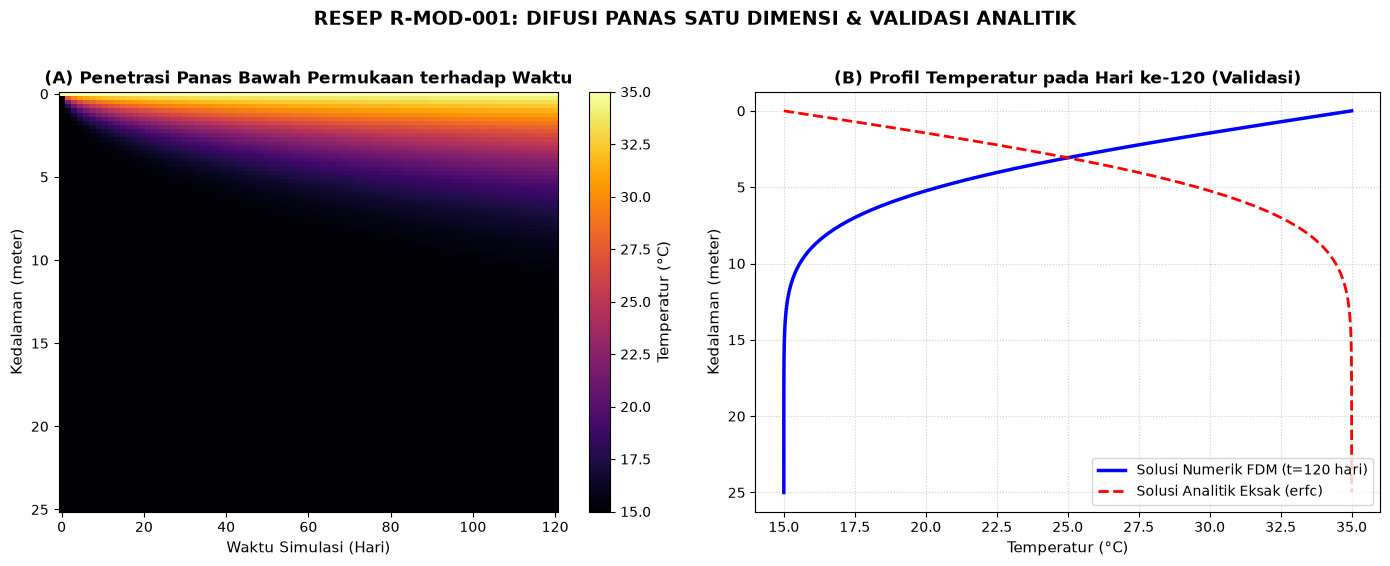

In [12]:
# 5. Visualisasi Hasil Simulasi Termal Bawah Permukaan
fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))

# Subplot A: Heatmap Profil Penetrasi Suhu vs Waktu
c = axes[0].pcolormesh(time_days_history, z, history_T.T, shading="auto", cmap="inferno")
axes[0].invert_yaxis()  # Kedalaman bumi bertambah ke bawah
axes[0].set_title("(A) Penetrasi Panas Bawah Permukaan terhadap Waktu", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Waktu Simulasi (Hari)", fontsize=11)
axes[0].set_ylabel("Kedalaman (meter)", fontsize=11)
cbar = fig.colorbar(c, ax=axes[0])
cbar.set_label("Temperatur (°C)", fontsize=11)

# Subplot B: Validasi Profil Suhu Numerik vs Analitik pada Hari ke-120
axes[1].plot(temperature, z, 'b-', linewidth=2.5, label=f"Solusi Numerik FDM (t={duration_days:.0f} hari)")
axes[1].plot(T_analytic, z, 'r--', linewidth=2.0, label=f"Solusi Analitik Eksak (erfc)")
axes[1].invert_yaxis()
axes[1].set_title(f"(B) Profil Temperatur pada Hari ke-{duration_days:.0f} (Validasi)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Temperatur (°C)", fontsize=11)
axes[1].set_ylabel("Kedalaman (meter)", fontsize=11)
axes[1].grid(True, linestyle=":", alpha=0.6)
axes[1].legend(loc="lower right", fontsize=10)

plt.suptitle("RESEP R-MOD-001: DIFUSI PANAS SATU DIMENSI & VALIDASI ANALITIK", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

#### Analisis Resep 2:
- Perpindahan panas dari permukaan merambat ke bawah tanah secara konduksi gradual seiring bertambahnya waktu.
- Perbandingan antara kurva numerik (FDM) dan analitik ($erfc$) menunjukkan kecocokan yang sangat tinggi dengan *error* absolut maksimum yang sangat kecil ($< 0.05^\circ\text{C}$), membuktikan bahwa skema diskritisasi numerik berhasil diverifikasi.